# Experiment 02: Temporal patterns and time zones

Card: [exp02_time_zones.md](../../experiments/exp02_time_zones.md)

In [ ]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import METERS, UTC_OFFSET
from ashrae.data import read_building, read_readings, read_weather

SMOKE = os.environ.get("SMOKE") == "1"
if SMOKE:
    N_READINGS = 200_000  # training rows kept after loading
    FIGURE = None
else:
    N_READINGS = None  # all 20.2M
    FIGURE = "../../figures/exp02_time_zones.png"

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90

In [ ]:
building, train, weather = read_building(), read_readings("train.csv"), read_weather("weather_train.csv")
if N_READINGS:
    train = train.sample(N_READINGS, random_state=0)

## Temporal patterns

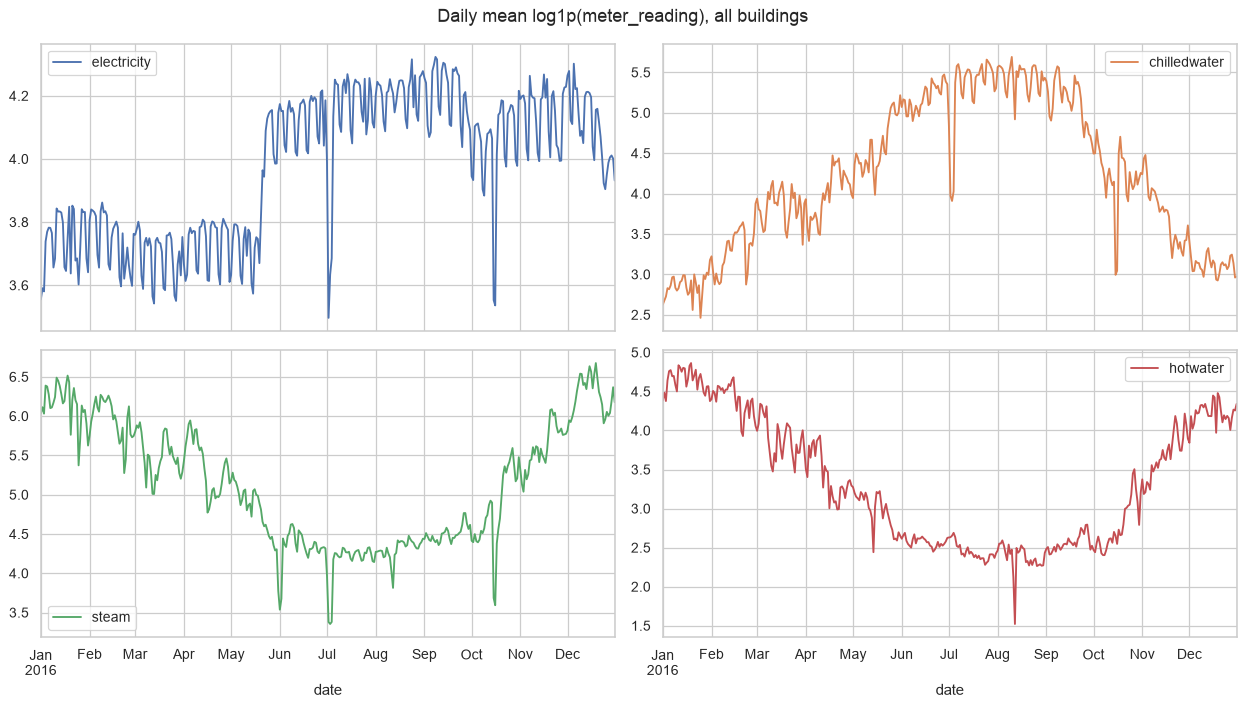

In [ ]:
daily = (
    train.assign(
        date=train.timestamp.dt.floor("D"), log_reading=np.log1p(train.meter_reading)
    )
    .groupby(["meter", "date"])
    .log_reading.mean()
    .unstack(0)
    .rename(columns=METERS)
)
daily.plot(
    subplots=True,
    figsize=(14, 8),
    layout=(2, 2),
    title="Daily mean log1p(meter_reading), all buildings",
)
plt.tight_layout()

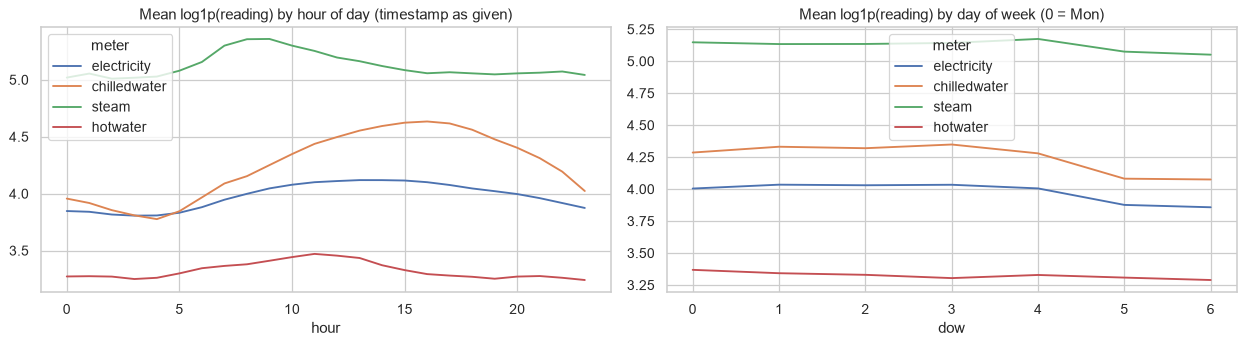

In [ ]:
hour_prof = (
    train.assign(
        hour=train.timestamp.dt.hour, log_reading=np.log1p(train.meter_reading)
    )
    .groupby(["meter", "hour"])
    .log_reading.mean()
    .unstack(0)
    .rename(columns=METERS)
)
dow_prof = (
    train.assign(
        dow=train.timestamp.dt.dayofweek, log_reading=np.log1p(train.meter_reading)
    )
    .groupby(["meter", "dow"])
    .log_reading.mean()
    .unstack(0)
    .rename(columns=METERS)
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
hour_prof.plot(
    ax=axes[0], title="Mean log1p(reading) by hour of day (timestamp as given)"
)
dow_prof.plot(ax=axes[1], title="Mean log1p(reading) by day of week (0 = Mon)")
plt.tight_layout()

## Time zones

In [ ]:
# Site locations from the Kaggle discussion; their UTC offsets are UTC_OFFSET in ashrae/config.py
SITE_LOCATION = {
    0: "Orlando, FL", 1: "UK (likely Southampton)", 2: "Tempe, AZ", 3: "Washington, DC",
    4: "US Pacific (likely Berkeley)", 5: "UK", 6: "US Eastern", 7: "Montreal/Ottawa",
    8: "Orlando, FL", 9: "Austin, TX", 10: "US Mountain", 11: "Montreal/Ottawa",
    12: "Ireland", 13: "Minneapolis-St Paul, MN", 14: "Charlottesville, VA", 15: "US Eastern",
}

elec = train[(train.meter == 0) & (train.meter_reading > 0)].merge(
    building[["building_id", "site_id"]], on="building_id"
)
elec["relative"] = elec.meter_reading / elec.groupby("building_id").meter_reading.transform("mean")

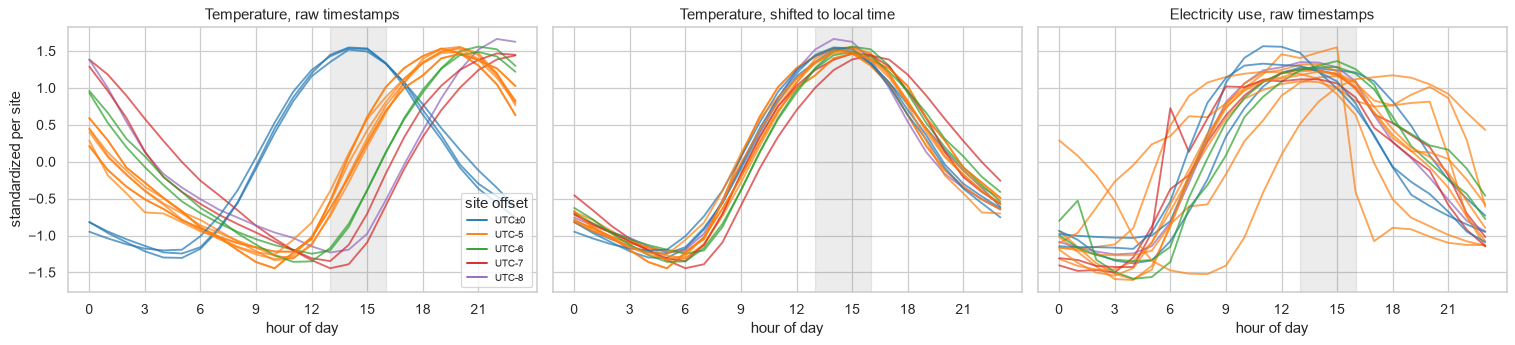

In [ ]:
def hourly_profile(df, value, offsets=None):
    hour = df.timestamp.dt.hour
    if offsets is not None:
        hour = (hour + df.site_id.map(offsets)) % 24
    profile = df.assign(hour=hour).groupby(["site_id", "hour"])[value].mean().unstack(0)
    return (profile - profile.mean()) / profile.std()  # standardized per site, so sites share one scale


panels = [
    ("Temperature, raw timestamps", hourly_profile(weather, "air_temperature")),
    ("Temperature, shifted to local time", hourly_profile(weather, "air_temperature", UTC_OFFSET)),
    ("Electricity use, raw timestamps", hourly_profile(elec, "relative")),
]
colors = {0: "tab:blue", -5: "tab:orange", -6: "tab:green", -7: "tab:red", -8: "tab:purple"}

fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, (title, profile) in zip(axes, panels):
    for site in profile.columns:
        ax.plot(profile.index, profile[site], color=colors[UTC_OFFSET[site]], alpha=0.7)
    ax.axvspan(13, 16, color="gray", alpha=0.15)
    ax.set(title=title, xlabel="hour of day", xticks=range(0, 24, 3))
axes[0].set_ylabel("standardized per site")
axes[0].legend(
    handles=[plt.Line2D([], [], color=c, label=f"UTC{o:+d}" if o else "UTC±0") for o, c in colors.items()],
    title="site offset",
    fontsize=8,
)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")

In [ ]:
# Hour shift that best lines up each site's electricity profile with the average of the other sites
def best_alignment(profile, site):
    others = profile.drop(columns=site).mean(axis=1)
    corr = pd.Series(
        {k: np.corrcoef(np.roll(profile[site].to_numpy(), -k), others)[0, 1] for k in range(-12, 12)}
    )
    return {"shift": corr.idxmax(), "corr_best": corr.max(), "corr_none": corr[0]}


alignment = pd.DataFrame({s: best_alignment(panels[2][1], s) for s in UTC_OFFSET}).T
site14 = alignment.loc[14]
print(f"site 14: best shift {site14['shift']:+.0f} h, correlation {site14['corr_none']:.2f} -> {site14['corr_best']:.2f}")
print(f"other sites: best shift within ±{alignment.drop(14)['shift'].abs().max():.0f} h")
del elec

site 14: best shift +5 h, correlation 0.24 -> 0.99
other sites: best shift within ±3 h
